     alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
0      14.23        1.71  2.43               15.6      127.0           2.80   
1      13.20        1.78  2.14               11.2      100.0           2.65   
2      13.16        2.36  2.67               18.6      101.0           2.80   
3      14.37        1.95  2.50               16.8      113.0           3.85   
4      13.24        2.59  2.87               21.0      118.0           2.80   
..       ...         ...   ...                ...        ...            ...   
173    13.71        5.65  2.45               20.5       95.0           1.68   
174    13.40        3.91  2.48               23.0      102.0           1.80   
175    13.27        4.28  2.26               20.0      120.0           1.59   
176    13.17        2.59  2.37               20.0      120.0           1.65   
177    14.13        4.10  2.74               24.5       96.0           2.05   

     flavanoids  nonflavanoid_phenols  proanthocyan

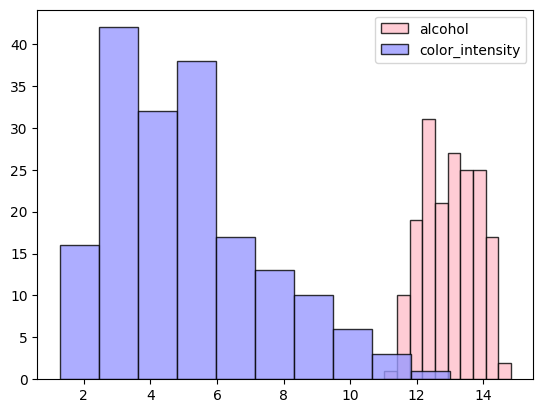

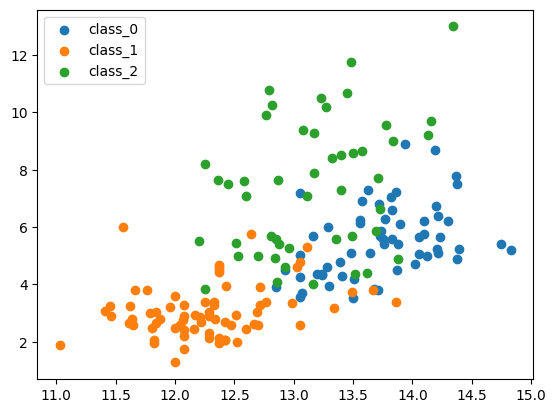

[[1.         0.96551724 1.         1.         1.        ]]
0.993103448275862
[[1.         0.93103448 1.         0.96428571 1.        ]]
0.9790640394088669


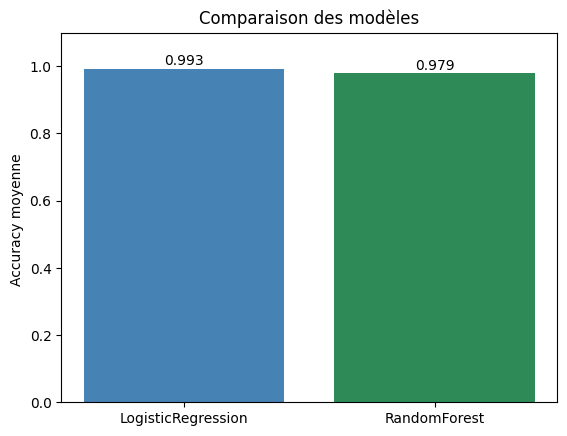

[0 1 0 1 1 0 0 1 1 2 1 2 0 2 0 1 1 0 1 0 1 1 0 0 1 1 0 2 1 2 0 2 1 2 2 2]
0.9722222222222222
[[12  0  0]
 [ 0 14  0]
 [ 0  1  9]]
[0 1 0 1 1 0 0 1 1 2 1 1 0 1 0 1 1 2 2 0 1 1 0 0 1 1 0 1 1 2 0 0 1 1 1 2]


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split,cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score,confusion_matrix
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

donnee=load_wine()
df=pd.DataFrame(donnee.data,columns=donnee.feature_names)
df['target']=donnee.target
print(df)
df.describe()
df.value_counts(df['target'])
donnee.feature_names

plt.hist(df['alcohol'],color='pink',label='alcohol',alpha=0.8,edgecolor='black')
plt.hist(df['color_intensity'],color='#99F',label='color_intensity',alpha=0.8,edgecolor='black')
plt.legend()
plt.show()

for i in sorted(df['target'].unique()):
   subset=df[df['target']==i]
   classe=donnee.target_names[i]
   plt.scatter(subset['alcohol'],subset['color_intensity'],label=classe)
plt.legend()
plt.show()

x_train, x_test, y_train, y_test = train_test_split(
    df.drop(columns=["target"]), df['target'], test_size=0.2, random_state=42, stratify=df['target']
)
pipeline1 = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression())
])

pipeline2=Pipeline([
    ("scaler", StandardScaler()),
    ("model",RandomForestClassifier())
])

arr1=np.array([cross_val_score(pipeline1,x_train,y_train,cv=5)])
print(arr1)
print(np.mean(arr1))

arr2=np.array([cross_val_score(pipeline2,x_train,y_train,cv=5)])
print(arr2)
print(np.mean(arr2))

noms = ["LogisticRegression", "RandomForest"]
moyennes = [arr1.mean(), arr2.mean()]
plt.bar(noms, moyennes, color=["steelblue", "seagreen"])
for i, m in enumerate(moyennes):
    plt.text(i, m + 0.01, f"{m:.3f}", ha="center")

plt.ylabel("Accuracy moyenne ")
plt.title("Comparaison des modèles")
plt.ylim(0, 1.1)
plt.show()

pipeline1.fit(x_train,y_train)
y_pred=pipeline1.predict(x_test)
print(y_pred)
print(accuracy_score(y_test,y_pred))
print(confusion_matrix(y_test,y_pred))

pca=PCA(n_components=2)
pca.fit(x_train)
x_train_pca=pca.transform(x_train)
x_test_pca=pca.transform(x_test)

pipeline1.fit(x_train_pca,y_train)
y_pred=pipeline1.predict(x_test_pca)
print(y_pred)